In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import tensorflow as tf
import numpy as np
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from tensorflow.keras.layers import (Input, Conv1D, BatchNormalization, MaxPooling1D,
                                   Dropout, MultiHeadAttention, LSTM, Bidirectional,
                                   Flatten, Dense)
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import precision_recall_fscore_support

In [2]:
trn = pd.read_csv("../input/nslkdd/kdd_train.csv")

In [3]:
trn.head()

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,labels
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,25,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal
1,0,udp,other,SF,146,0,0,0,0,0,...,1,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal
2,0,tcp,private,S0,0,0,0,0,0,0,...,26,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune
3,0,tcp,http,SF,232,8153,0,0,0,0,...,255,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal
4,0,tcp,http,SF,199,420,0,0,0,0,...,255,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal


In [4]:
trn.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 125973 entries, 0 to 125972
Data columns (total 42 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   duration                     125973 non-null  int64  
 1   protocol_type                125973 non-null  object 
 2   service                      125973 non-null  object 
 3   flag                         125973 non-null  object 
 4   src_bytes                    125973 non-null  int64  
 5   dst_bytes                    125973 non-null  int64  
 6   land                         125973 non-null  int64  
 7   wrong_fragment               125973 non-null  int64  
 8   urgent                       125973 non-null  int64  
 9   hot                          125973 non-null  int64  
 10  num_failed_logins            125973 non-null  int64  
 11  logged_in                    125973 non-null  int64  
 12  num_compromised              125973 non-null  int64  
 13 

In [5]:
trn.isnull().sum()

duration                       0
protocol_type                  0
service                        0
flag                           0
src_bytes                      0
dst_bytes                      0
land                           0
wrong_fragment                 0
urgent                         0
hot                            0
num_failed_logins              0
logged_in                      0
num_compromised                0
root_shell                     0
su_attempted                   0
num_root                       0
num_file_creations             0
num_shells                     0
num_access_files               0
num_outbound_cmds              0
is_host_login                  0
is_guest_login                 0
count                          0
srv_count                      0
serror_rate                    0
srv_serror_rate                0
rerror_rate                    0
srv_rerror_rate                0
same_srv_rate                  0
diff_srv_rate                  0
srv_diff_h

In [6]:
trn.nunique()

duration                       2981
protocol_type                     3
service                          70
flag                             11
src_bytes                      3341
dst_bytes                      9326
land                              2
wrong_fragment                    3
urgent                            4
hot                              28
num_failed_logins                 6
logged_in                         2
num_compromised                  88
root_shell                        2
su_attempted                      3
num_root                         82
num_file_creations               35
num_shells                        3
num_access_files                 10
num_outbound_cmds                 1
is_host_login                     2
is_guest_login                    2
count                           512
srv_count                       509
serror_rate                      89
srv_serror_rate                  86
rerror_rate                      82
srv_rerror_rate             

In [7]:
trn.duplicated().sum()

0

In [8]:
types = trn["labels"].unique()
types

array(['normal', 'neptune', 'warezclient', 'ipsweep', 'portsweep',
       'teardrop', 'nmap', 'satan', 'smurf', 'pod', 'back',
       'guess_passwd', 'ftp_write', 'multihop', 'rootkit',
       'buffer_overflow', 'imap', 'warezmaster', 'phf', 'land',
       'loadmodule', 'spy', 'perl'], dtype=object)

In [9]:
types = types[1:]
types

array(['neptune', 'warezclient', 'ipsweep', 'portsweep', 'teardrop',
       'nmap', 'satan', 'smurf', 'pod', 'back', 'guess_passwd',
       'ftp_write', 'multihop', 'rootkit', 'buffer_overflow', 'imap',
       'warezmaster', 'phf', 'land', 'loadmodule', 'spy', 'perl'],
      dtype=object)

In [10]:
trn["labels"].replace(to_replace=types,value="attacking", inplace = True)

<ipython-input-10-cf270ae3cc4d>:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  trn["labels"].replace(to_replace=types,value="attacking", inplace = True)


In [11]:
trn.head()

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,labels
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,25,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal
1,0,udp,other,SF,146,0,0,0,0,0,...,1,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal
2,0,tcp,private,S0,0,0,0,0,0,0,...,26,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,attacking
3,0,tcp,http,SF,232,8153,0,0,0,0,...,255,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal
4,0,tcp,http,SF,199,420,0,0,0,0,...,255,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal


In [12]:
fig = px.pie(trn, values=trn['labels'].value_counts(), names=trn['labels'].unique(), title='Labels',width = 500, height = 500)
fig.show()

<Axes: xlabel='count', ylabel='protocol_type'>

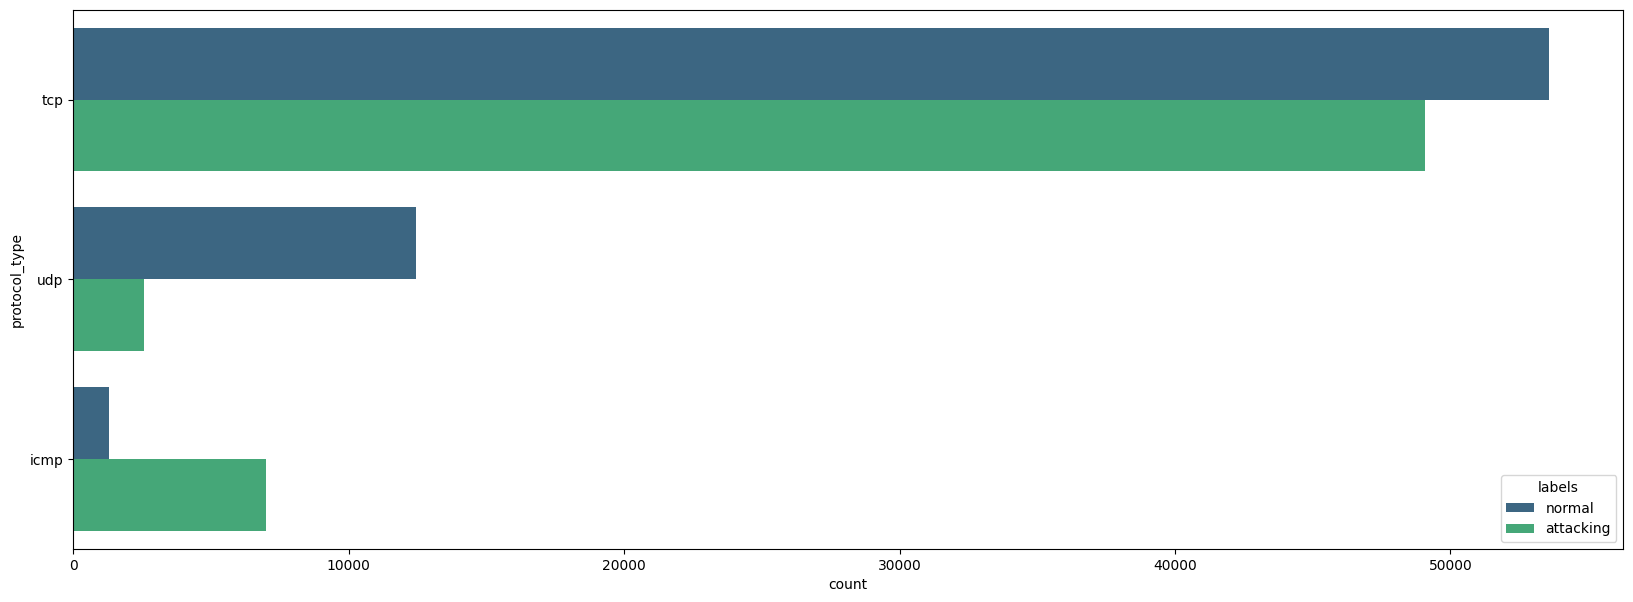

In [13]:
plt.figure(figsize = (20,7))
sns.countplot(data=trn, y=trn.protocol_type , hue = 'labels', palette="viridis")

<Axes: xlabel='count', ylabel='service'>

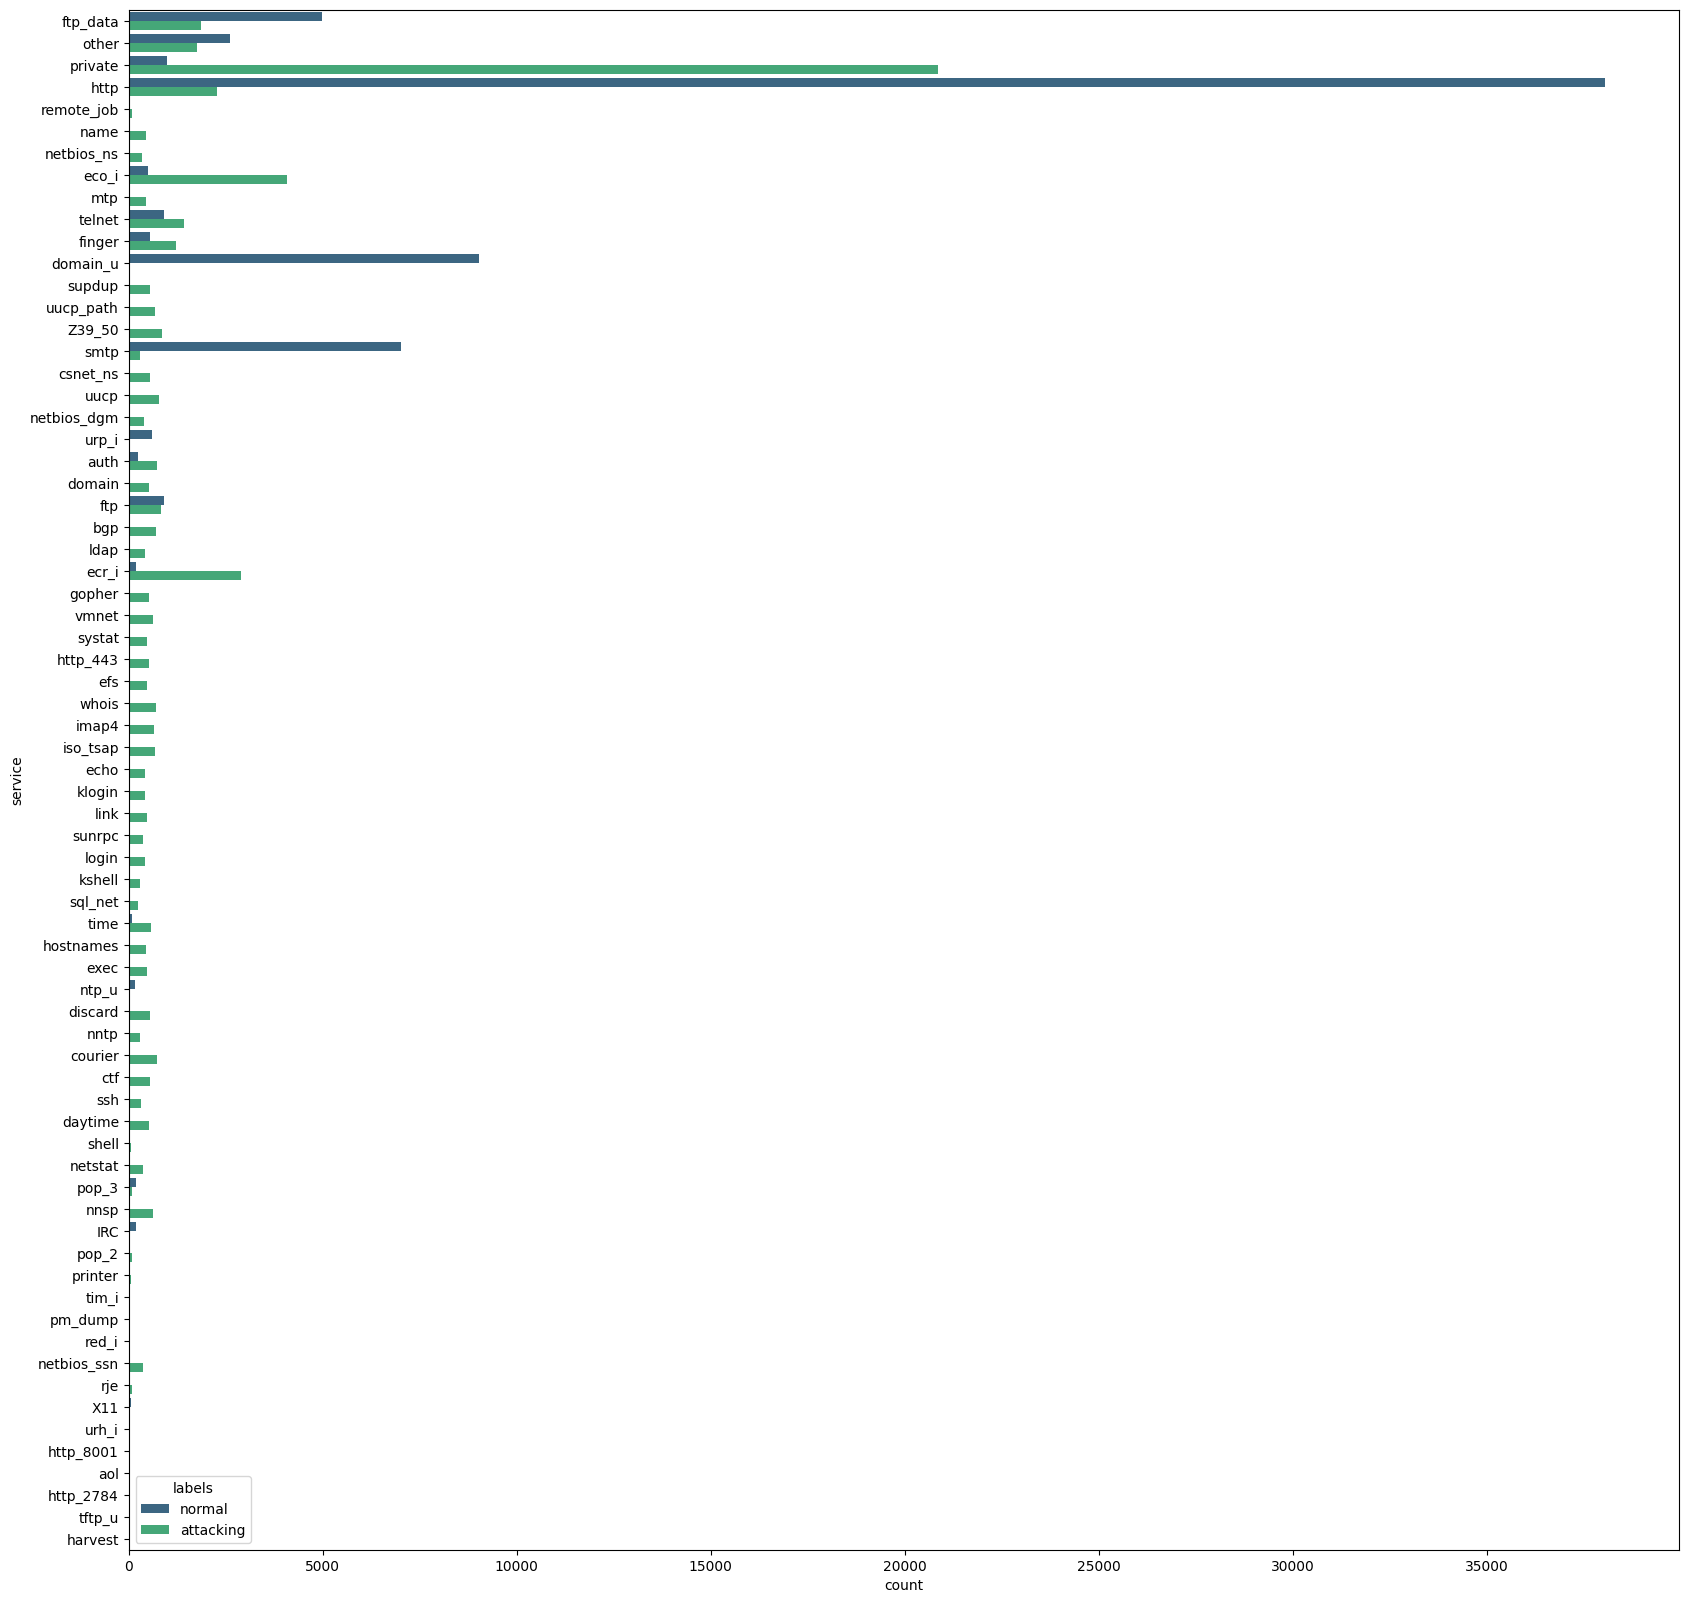

In [14]:
plt.figure(figsize = (20,20))
sns.countplot(data=trn, y=trn.service, hue = 'labels', palette="viridis")

<Axes: xlabel='count', ylabel='flag'>

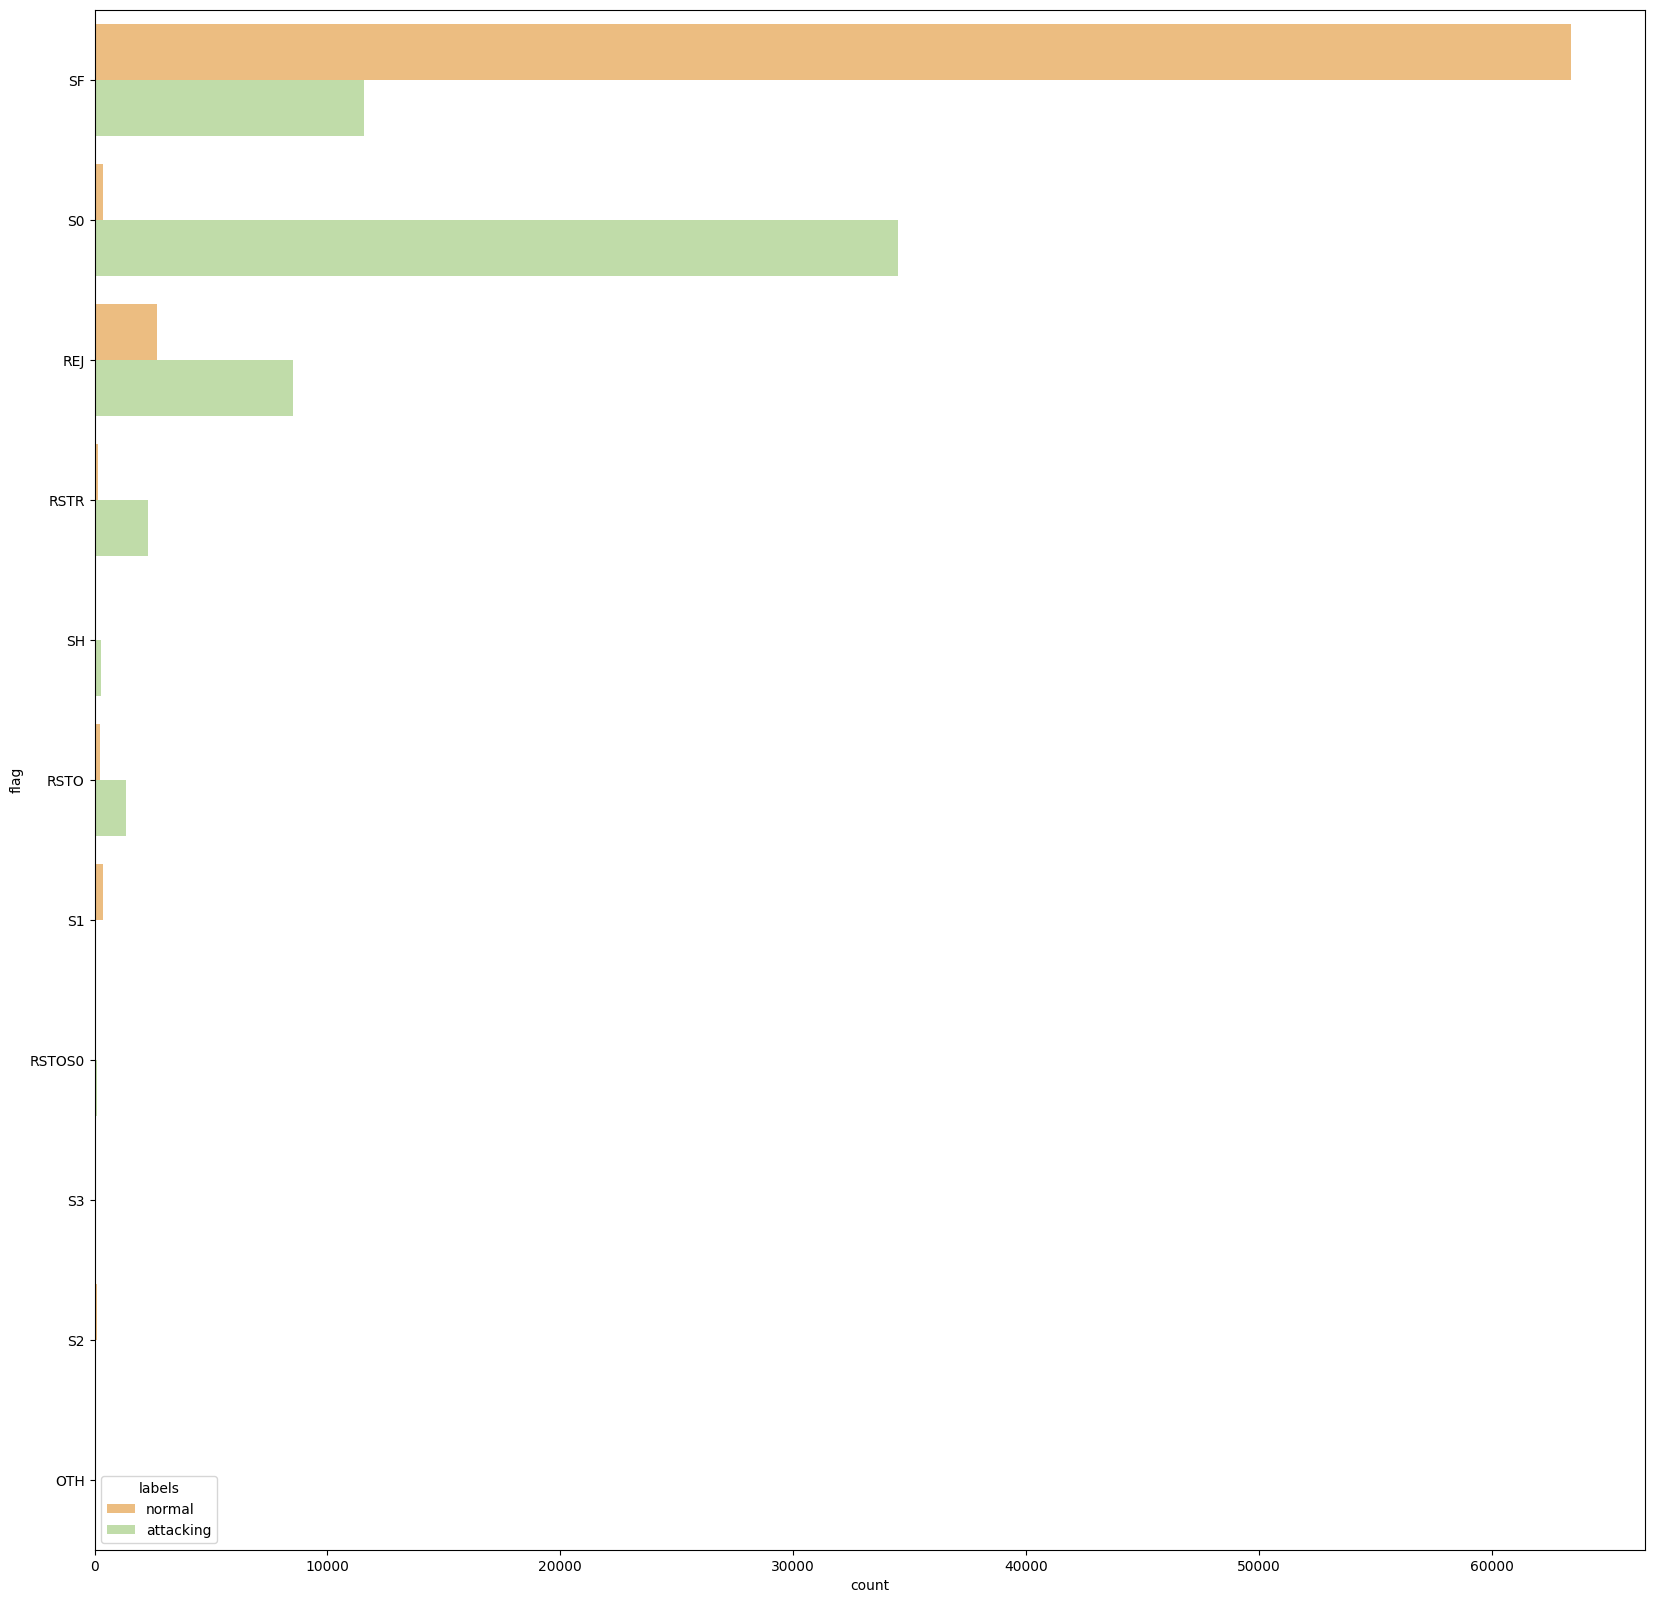

In [15]:
plt.figure(figsize = (20,20))
sns.countplot(data=trn, y=trn.flag, hue="labels" , palette="Spectral")

In [16]:
c = len(trn.select_dtypes(include=["number"]).columns)
c

38

In [17]:
cols = ['duration', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment',
       'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised',
       'root_shell', 'su_attempted', 'num_root', 'num_file_creations',
       'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login',
       'is_guest_login', 'count', 'srv_count', 'serror_rate',
       'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate',
       'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count',
       'dst_host_srv_count', 'dst_host_same_srv_rate',
       'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate',
       'dst_host_srv_diff_host_rate', 'dst_host_serror_rate',
       'dst_host_srv_serror_rate', 'dst_host_rerror_rate',
       'dst_host_srv_rerror_rate']

In [18]:
def create_plot_pivot(df, x_column):
    """ Create a pivot table for satisfaction versus another rating for easy plotting. """
    _df_plot = df.groupby([x_column, 'labels']).size() \
    .reset_index().pivot(columns='labels', index=x_column, values=0)
    return _df_plot

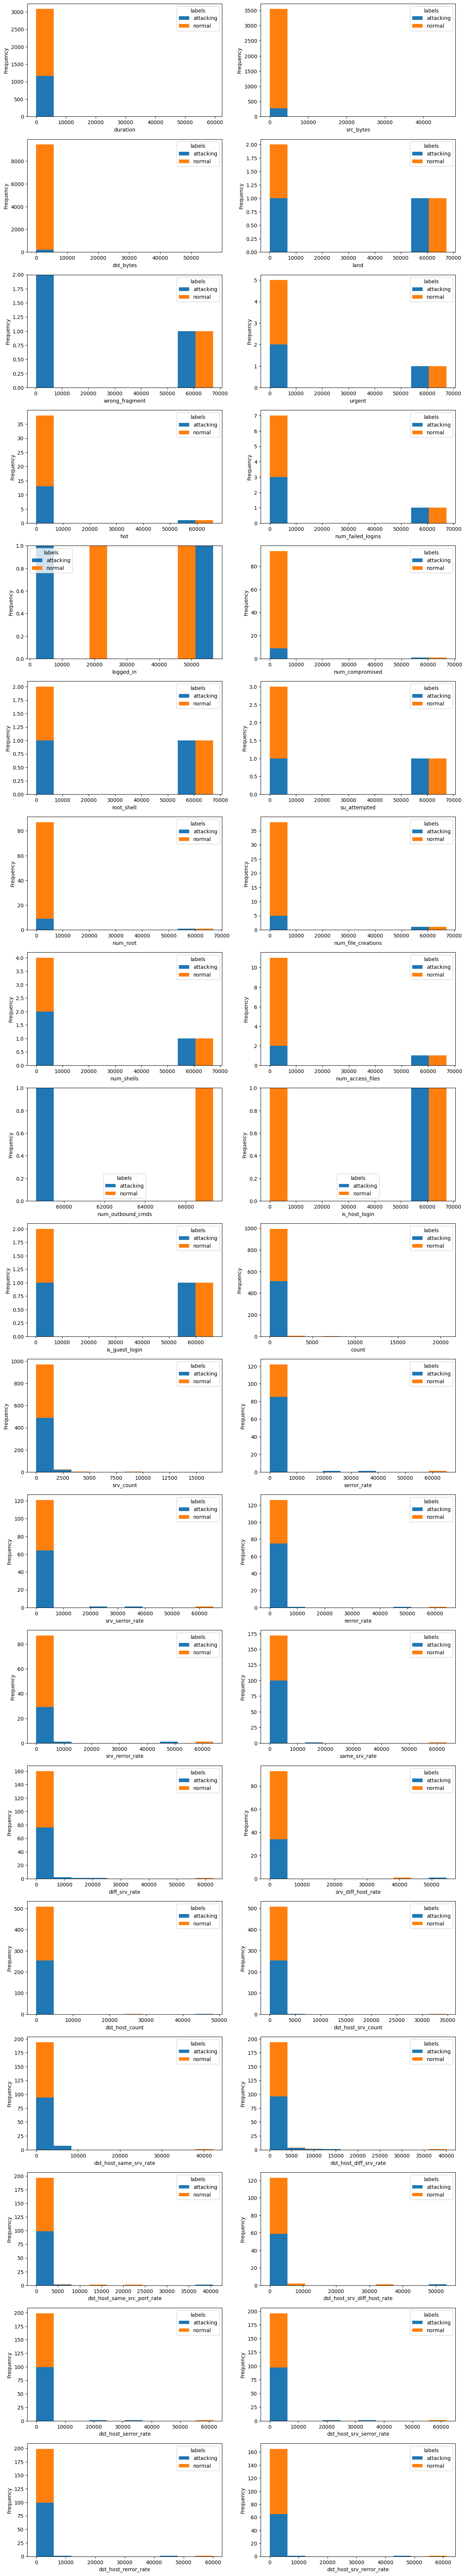

In [19]:
fig, ax = plt.subplots(19, 2, figsize=(15,90))
axe = ax.ravel()

for i in range(c):
    create_plot_pivot(trn, cols[i]).plot(kind='hist',stacked=True, ax=axe[i])
    axe[i].set_xlabel(cols[i])
    
fig.show()

In [20]:
for col in trn.select_dtypes(include=["object"]):
    print(col)

protocol_type
service
flag
labels


In [21]:
from sklearn.preprocessing import LabelEncoder

cols = ['protocol_type','service','flag','labels']

for i in cols:
    en = LabelEncoder()
    
    trn[i] = en.fit_transform(trn[i])

In [22]:
trn.head()

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,labels
0,0,1,20,9,491,0,0,0,0,0,...,25,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,1
1,0,2,44,9,146,0,0,0,0,0,...,1,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,1
2,0,1,49,5,0,0,0,0,0,0,...,26,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,0
3,0,1,24,9,232,8153,0,0,0,0,...,255,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,1
4,0,1,24,9,199,420,0,0,0,0,...,255,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1


/usr/local/lib/python3.10/dist-packages/matplotlib/colors.py:721: RuntimeWarning:

invalid value encountered in less



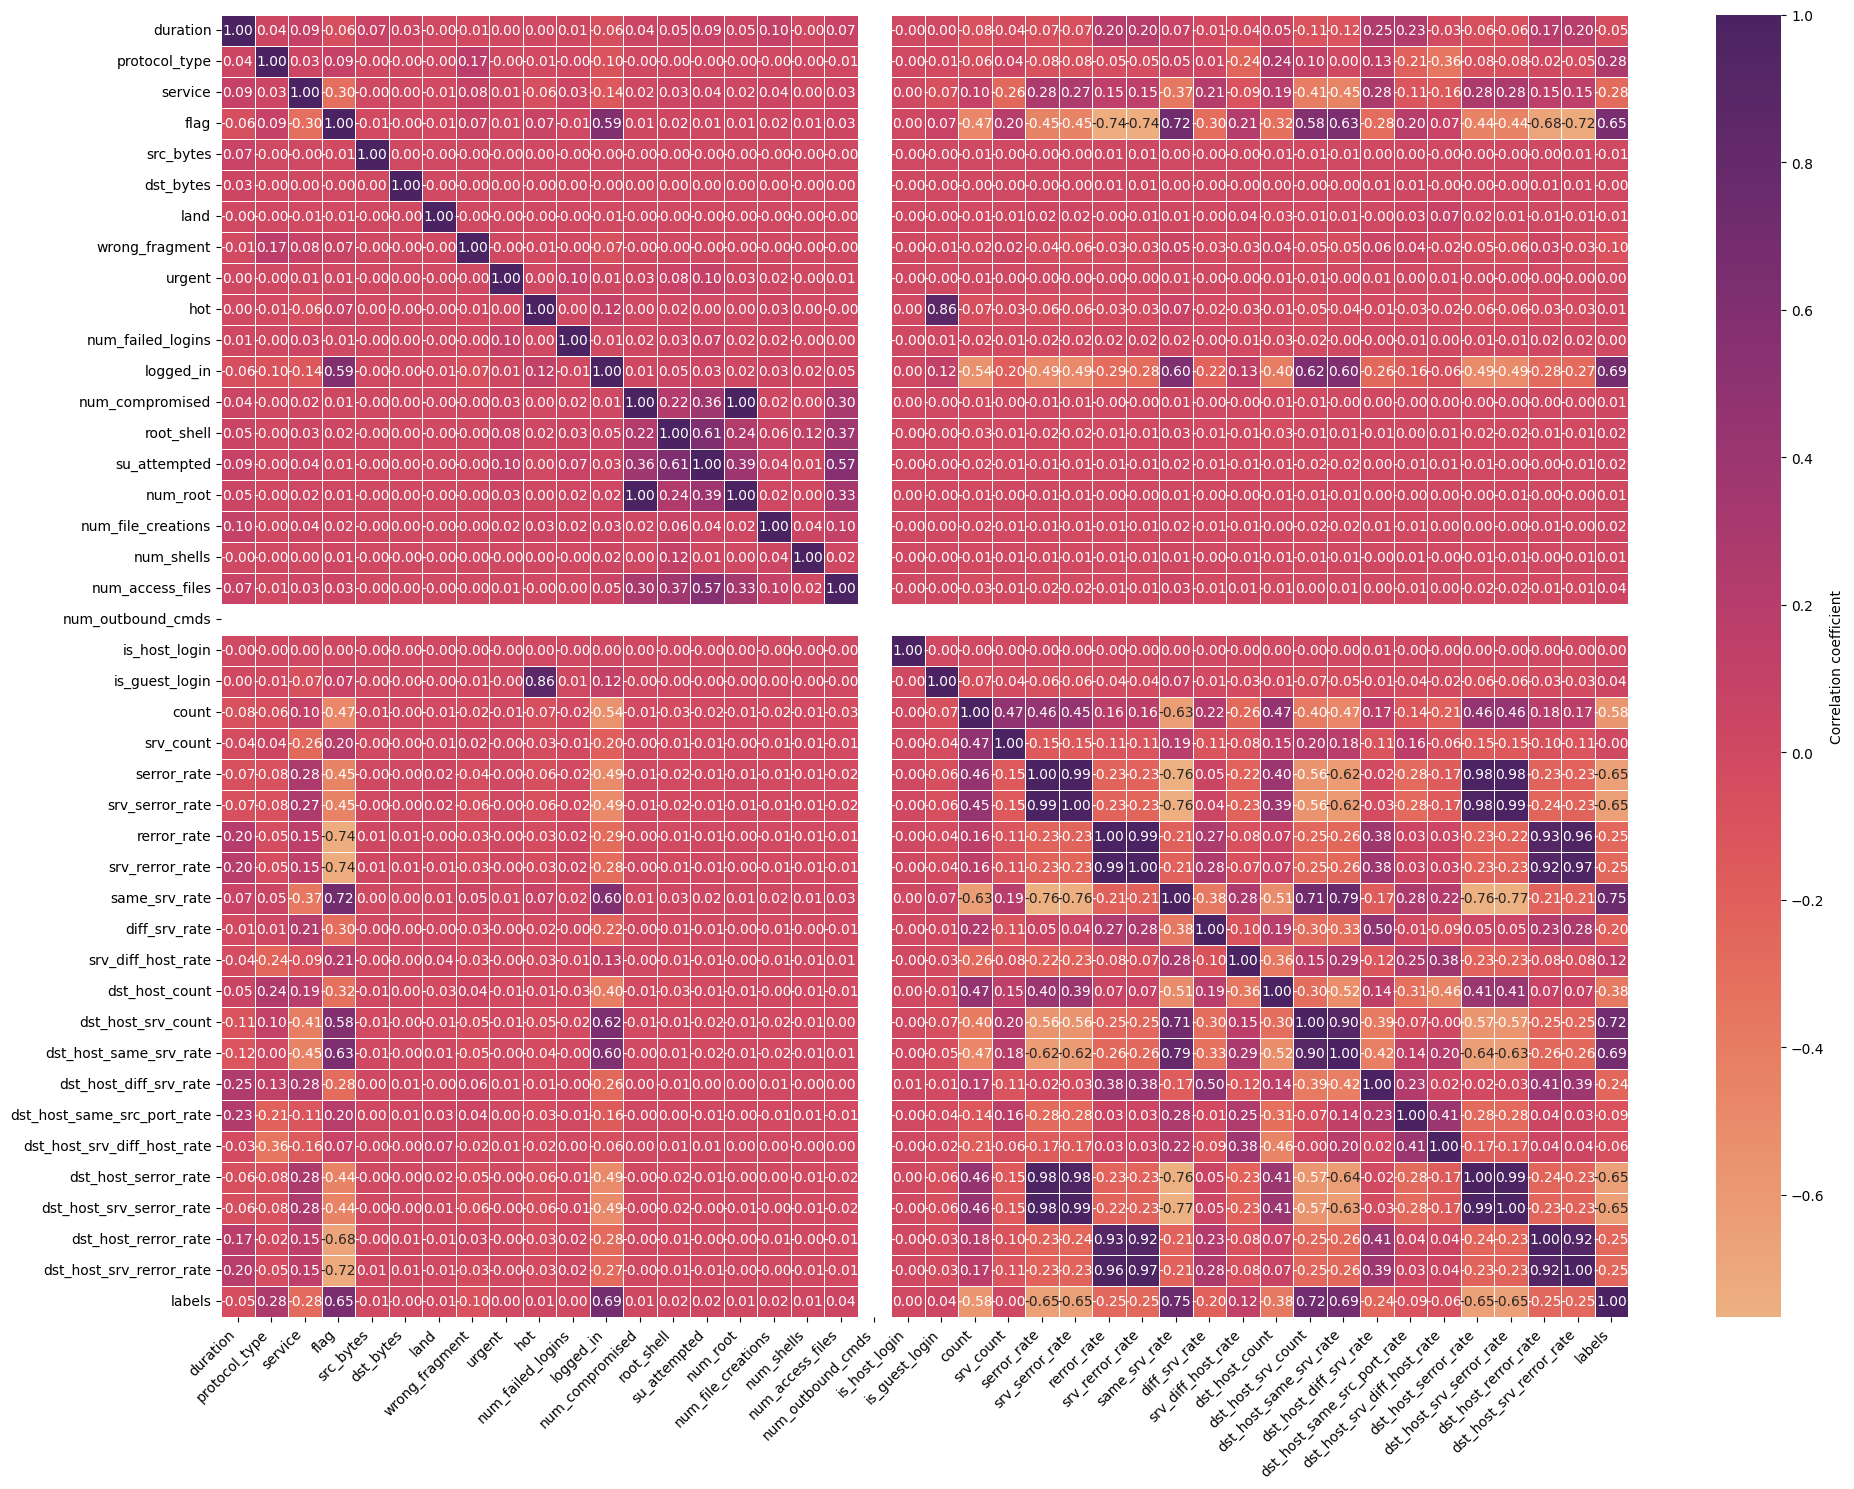

'/kaggle/working/nsl_kdd_heatmap_with_labels.png'

In [23]:
# Select only numeric columns
numeric_trn = trn.select_dtypes(include=['number'])

# Generate the heatmap using only numeric columns
plt.figure(figsize=(20, 15))  # Adjust the figure size for better visibility
sns.heatmap(numeric_trn.corr(), annot=True, cmap='flare', fmt='.2f', linewidths=0.5, cbar_kws={'label': 'Correlation coefficient'})

# Improve readability by rotating the labels
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

# Save the heatmap to the Kaggle directory
file_path = '/kaggle/working/nsl_kdd_heatmap_with_labels.png'
plt.tight_layout()
plt.savefig(file_path)

# Display the heatmap
plt.show()

file_path


In [24]:
# Create correlation matrix
corr_matrix = trn.corr().abs()
corr_matrix

/usr/local/lib/python3.10/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning:

invalid value encountered in greater

/usr/local/lib/python3.10/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning:

invalid value encountered in less

/usr/local/lib/python3.10/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning:

invalid value encountered in greater

/usr/local/lib/python3.10/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning:

invalid value encountered in greater

/usr/local/lib/python3.10/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning:

invalid value encountered in less

/usr/local/lib/python3.10/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning:

invalid value encountered in greater



,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,labels
duration,1.000000,0.038241,0.092858,0.063390,0.070737,0.034878,0.001553,0.009866,0.003830,0.000705,...,0.109776,0.116005,0.254195,0.228737,0.026669,0.064948,0.064361,0.173815,0.199024,0.048785
protocol_type,0.038241,1.000000,0.029994,0.093668,0.000974,0.000608,0.001757,0.169535,0.000965,0.011857,...,0.103919,0.001702,0.131380,0.209105,0.356183,0.079398,0.077925,0.015434,0.046938,0.281355
service,0.092858,0.029994,1.000000,0.304014,0.001631,0.003596,0.009952,0.084404,0.010980,0.064066,...,0.407696,0.452696,0.284072,0.111163,0.156211,0.281635,0.277594,0.150666,0.148405,0.276548
flag,0.063390,0.093668,0.304014,1.000000,0.008114,0.004096,0.010373,0.067214,0.005811,0.068437,...,0.582687,0.630118,0.283607,0.195689,0.073773,0.443441,0.443225,0.683310,0.718778,0.647073
src_bytes,0.070737,0.000974,0.001631,0.008114,1.000000,0.000204,0.000109,0.000693,0.000059,0.000295,...,0.006861,0.006572,0.000900,0.000431,0.001655,0.004503,0.003397,0.001468,0.012449,0.005921
dst_bytes,0.034878,0.000608,0.003596,0.004096,0.000204,1.000000,0.000069,0.000440,0.000248,0.000344,...,0.004224,0.004424,0.011031,0.011747,0.001281,0.003024,0.002944,0.011729,0.011223,0.004118
land,0.001553,0.001757,0.009952,0.010373,0.000109,0.000069,1.000000,0.001261,0.000109,0.001340,...,0.014159,0.011597,0.004516,0.033851,0.070474,0.019840,0.012276,0.005222,0.005303,0.007191
wrong_fragment,0.009866,0.169535,0.084404,0.067214,0.000693,0.000440,0.001261,1.000000,0.000692,0.008508,...,0.045240,0.048733,0.059797,0.037177,0.016252,0.051917,0.055917,0.028890,0.033682,0.095905
urgent,0.003830,0.000965,0.010980,0.005811,0.000059,0.000248,0.000109,0.000692,1.000000,0.000293,...,0.007897,0.004489,0.006840,0.002741,0.005176,0.004749,0.004834,0.002999,0.002912,0.002787
hot,0.000705,0.011857,0.064066,0.068437,0.000295,0.000344,0.001340,0.008508,0.000293,1.000000,...,0.051864,0.036293,0.012293,0.034536,0.024715,0.058222,0.058214,0.030555,0.031670,0.013083


In [25]:
# Select upper triangle of correlation matrix
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

In [26]:
# Find features with correlation greater than 0.95
to_drop = [column for column in upper.columns if any(upper[column] > 0.95)]
to_drop

/usr/local/lib/python3.10/dist-packages/pandas/core/computation/expressions.py:73: RuntimeWarning:

invalid value encountered in greater



['num_root',
 'srv_serror_rate',
 'srv_rerror_rate',
 'dst_host_serror_rate',
 'dst_host_srv_serror_rate',
 'dst_host_srv_rerror_rate']

In [27]:
# Drop features 
trn.drop(to_drop, axis=1, inplace=True)

In [28]:
X_trn = trn.drop(['labels'] , axis = 1).values
Y_trn = trn['labels'].values

In [29]:
scaler = StandardScaler()

X_trn = scaler.fit_transform(X_trn)

In [30]:
X_trn.shape

(125973, 35)

In [31]:
# First split: 70% train, 30% remaining (validation + test)
x_trn, x_temp, y_trn, y_temp = train_test_split(X_trn, Y_trn, test_size=0.30, random_state=42)

# Second split: Split the remaining 30% into 50% validation and 50% test (15% each)
x_val, x_tst, y_val, y_tst = train_test_split(x_temp, y_temp, test_size=0.50, random_state=42)

In [32]:
# Check the shapes of the resulting datasets
print("Training set shape:", x_trn.shape)
print("Validation set shape:", x_val.shape)
print("Test set shape:", x_tst.shape)

Training set shape: (88181, 35)
Validation set shape: (18896, 35)
Test set shape: (18896, 35)


In [33]:
# Reshape the data for CNN input
# CNN expects input shape: (samples, timesteps, features)
TIMESTEPS = 1  # Since each sample is a single time step
x_trn_reshaped = x_trn.reshape((x_trn.shape[0], TIMESTEPS, x_trn.shape[1]))
x_tst_reshaped = x_tst.reshape((x_tst.shape[0], TIMESTEPS, x_tst.shape[1]))

# Model parameters
INPUT_SHAPE = (TIMESTEPS, x_trn.shape[1])
EPOCHS = 50
BATCH_SIZE = 32

# Define the model architecture
def build_model_small_pool(input_shape):
    """CNN-BiLSTM model with small pool size and padding"""
    inputs = Input(shape=input_shape)
    
    # First CNN block 
    x = Conv1D(filters=64, kernel_size=3, activation='relu', padding='same')(inputs)
    x = BatchNormalization()(x)
    x = MaxPooling1D(pool_size=1, padding='same')(x)
    x = Dropout(0.4)(x)
    
    # Second CNN block 
    x = Conv1D(filters=128, kernel_size=3, activation='relu', padding='same')(x)
    x = BatchNormalization()(x)
    x = MaxPooling1D(pool_size=1, padding='same')(x)
    x = Dropout(0.4)(x)
    
    # MultiheadAttention layer
    attention_output = MultiHeadAttention(num_heads=2, key_dim=64)(x, x)
    x = tf.keras.layers.Add()([x, attention_output])
    x = BatchNormalization()(x)
    
    lstm_out = Bidirectional(LSTM(units=64, return_sequences=True))(x)
    lstm_out = Dropout(0.4)(lstm_out)
    
    x = Flatten()(lstm_out)
    x = Dense(64, activation='relu')(x)
    x = BatchNormalization()(x)
    x = Dropout(0.4)(x)
    
    outputs = Dense(1, activation='sigmoid')(x)
    
    return Model(inputs=inputs, outputs=outputs)

# Build and compile the model
model = build_model_small_pool(INPUT_SHAPE)
model.compile(optimizer='adam',
             loss='binary_crossentropy',
             metrics=['accuracy'])

In [34]:
# Callbacks for training
early_stopping = EarlyStopping(monitor='val_loss',
                             patience=5,
                             restore_best_weights=True)
model_checkpoint = ModelCheckpoint('best_model.keras',
                                 monitor='val_loss',
                                 save_best_only=True)

# Train the model
history = model.fit(x_trn_reshaped, y_trn,
                   epochs=EPOCHS,
                   batch_size=BATCH_SIZE,
                   validation_split=0.2,
                   callbacks=[early_stopping, model_checkpoint],
                   verbose=1)

# Evaluate the model
y_pred = model.predict(x_tst_reshaped)
y_pred_binary = (y_pred > 0.5).astype(int)


Epoch 1/50


/usr/local/lib/python3.10/dist-packages/keras/src/ops/nn.py:545: UserWarning:

You are using a softmax over axis 3 of a tensor of shape (None, 2, 1, 1). This axis has size 1. The softmax operation will always return the value 1, which is likely not what you intended. Did you mean to use a sigmoid instead?



2205/2205 ━━━━━━━━━━━━━━━━━━━━ 25s 8ms/step - accuracy: 0.9395 - loss: 0.1571 - val_accuracy: 0.9856 - val_loss: 0.0390
Epoch 2/50
2205/2205 ━━━━━━━━━━━━━━━━━━━━ 17s 8ms/step - accuracy: 0.9761 - loss: 0.0676 - val_accuracy: 0.9837 - val_loss: 0.0357
Epoch 3/50
2205/2205 ━━━━━━━━━━━━━━━━━━━━ 17s 8ms/step - accuracy: 0.9788 - loss: 0.0611 - val_accuracy: 0.9874 - val_loss: 0.0323
Epoch 4/50
2205/2205 ━━━━━━━━━━━━━━━━━━━━ 17s 8ms/step - accuracy: 0.9805 - loss: 0.0554 - val_accuracy: 0.9887 - val_loss: 0.0329
Epoch 5/50
2205/2205 ━━━━━━━━━━━━━━━━━━━━ 17s 8ms/step - accuracy: 0.9819 - loss: 0.0530 - val_accuracy: 0.9864 - val_loss: 0.0329
Epoch 6/50
2205/2205 ━━━━━━━━━━━━━━━━━━━━ 18s 8ms/step - accuracy: 0.9838 - loss: 0.0481 - val_accuracy: 0.9887 - val_loss: 0.0313
Epoch 7/50
2205/2205 ━━━━━━━━━━━━━━━━━━━━ 18s 8ms/step - accuracy: 0.9831 - loss: 0.0493 - val_accuracy: 0.9899 - val_loss: 0.0283
Epoch 8/50
2205/2205 ━━━━━━━━━━━━━━━━━━━━ 18s 8ms/step - accuracy: 0.9841 - loss: 0.0453 - val

/usr/local/lib/python3.10/dist-packages/keras/src/ops/nn.py:545: UserWarning:

You are using a softmax over axis 3 of a tensor of shape (32, 2, 1, 1). This axis has size 1. The softmax operation will always return the value 1, which is likely not what you intended. Did you mean to use a sigmoid instead?



591/591 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step



Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      8910
           1       0.99      0.99      0.99      9986

    accuracy                           0.99     18896
   macro avg       0.99      0.99      0.99     18896
weighted avg       0.99      0.99      0.99     18896



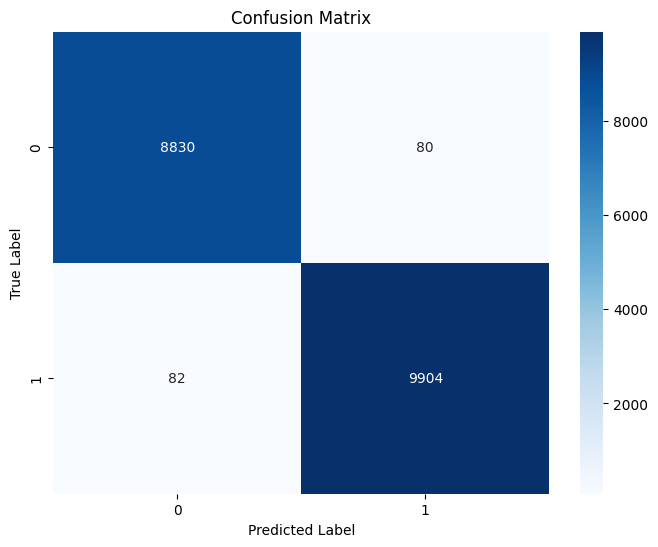

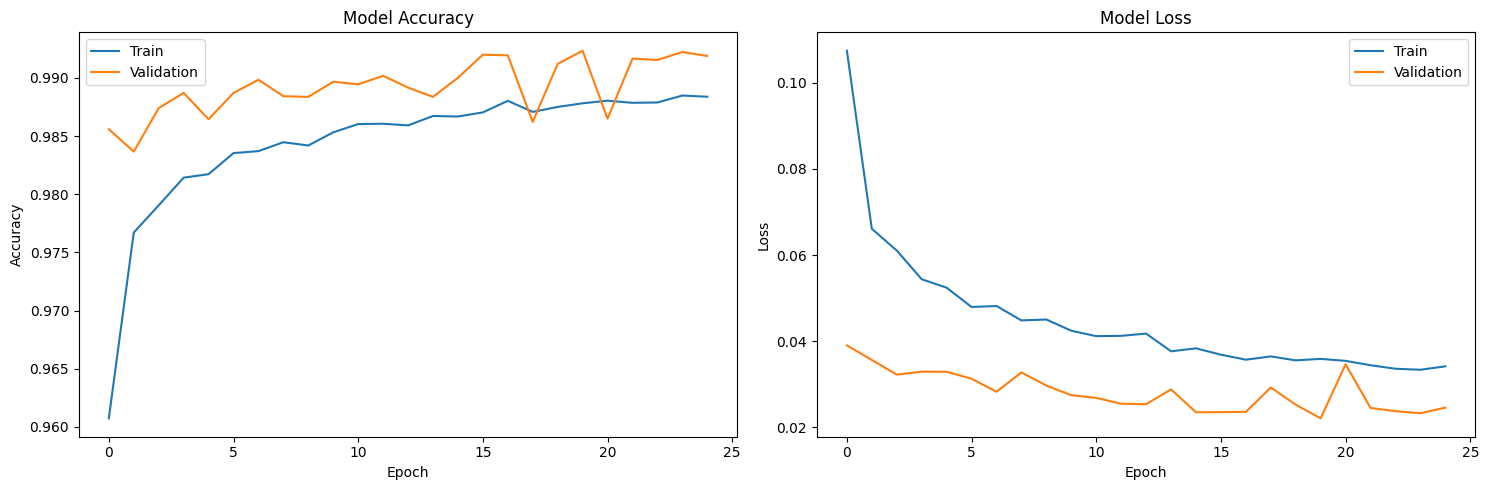

In [35]:
# Print classification report
print("\nClassification Report:")
print(classification_report(y_tst, y_pred_binary))

# Plot confusion matrix
def plot_confusion_matrix(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title('Confusion Matrix')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.show()

plot_confusion_matrix(y_tst, y_pred_binary)

# Plot training history
def plot_training_history(history):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
    
    # Plot accuracy
    ax1.plot(history.history['accuracy'])
    ax1.plot(history.history['val_accuracy'])
    ax1.set_title('Model Accuracy')
    ax1.set_ylabel('Accuracy')
    ax1.set_xlabel('Epoch')
    ax1.legend(['Train', 'Validation'])
    
    # Plot loss
    ax2.plot(history.history['loss'])
    ax2.plot(history.history['val_loss'])
    ax2.set_title('Model Loss')
    ax2.set_ylabel('Loss')
    ax2.set_xlabel('Epoch')
    ax2.legend(['Train', 'Validation'])
    
    plt.tight_layout()
    plt.show()

plot_training_history(history)

# Get training and validation metrics
final_train_accuracy = history.history['accuracy'][-1]
final_val_accuracy = history.history['val_accuracy'][-1]
final_train_loss = history.history['loss'][-1]
final_val_loss = history.history['val_loss'][-1]

# Get test accuracy
test_loss, test_accuracy = model.evaluate(x_tst_reshaped, y_tst, verbose=0)



=== Final Metrics ===
Training Accuracy: 0.9884
Validation Accuracy: 0.9919
Test Accuracy: 0.9914

Training Loss: 0.0342
Validation Loss: 0.0246
Test Loss: 0.0253

Detailed Classification Metrics

Per-class metrics:

Class 0:
Precision: 0.9908
Recall: 0.9910
F1-score: 0.9909
Support: 8910

Class 1:
Precision: 0.9920
Recall: 0.9918
F1-score: 0.9919
Support: 9986

Macro-averaged metrics:
Macro Precision: 0.9914
Macro Recall: 0.9914
Macro F1-score: 0.9914

=== Confusion Matrix (Percentages) ===
[[99.10213244  0.89786756]
 [ 0.82114961 99.17885039]]


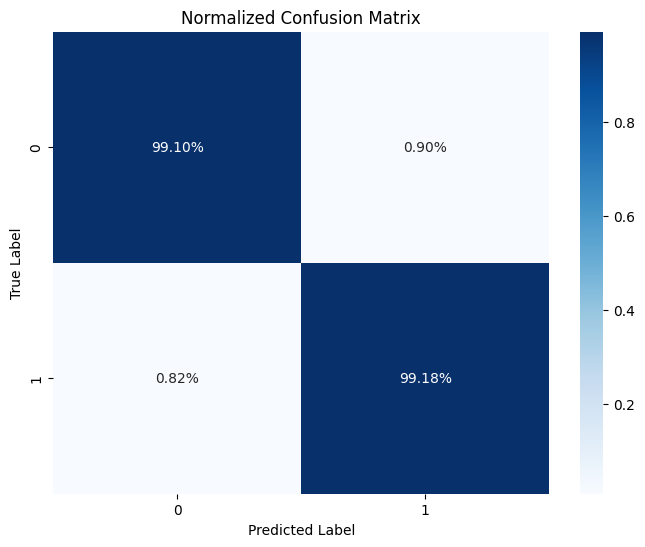

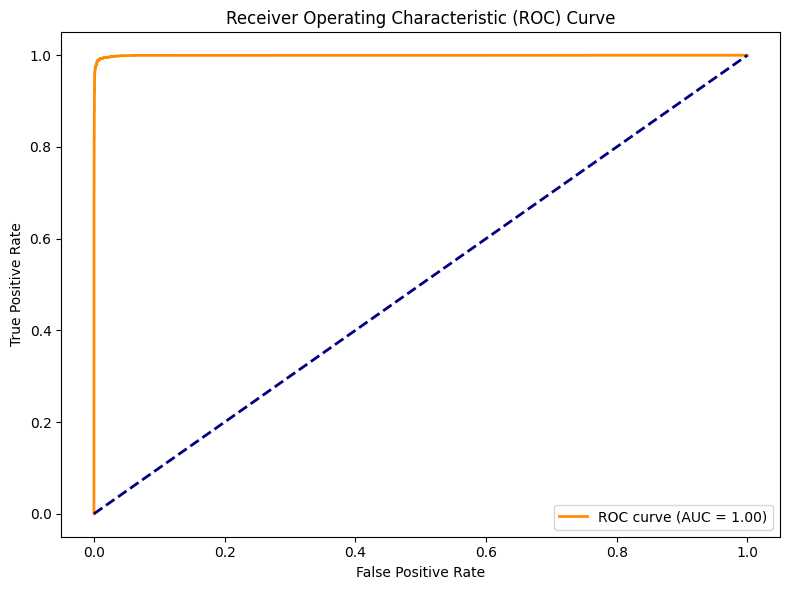


Model Summary:


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)  │ (None, 1, 35)          │              0 │ -                      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv1d (Conv1D)           │ (None, 1, 64)          │          6,784 │ input_layer[0][0]      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization       │ (None, 1, 64)          │            256 │ conv1d[0][0]           │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ max_pooling1d             │ (None, 1, 64)          │              0 │ batch_normalization[0… │
│ (MaxPooling1D)            │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dropout (Dropout)         │ (None, 1, 64)          │              0 │ max_pooling1d[0][0]    │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv1d_1 (Conv1D)         │ (None, 1, 128)         │         24,704 │ dropout[0][0]          │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_1     │ (None, 1, 128)         │            512 │ conv1d_1[0][0]         │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ max_pooling1d_1           │ (None, 1, 128)         │              0 │ batch_normalization_1… │
│ (MaxPooling1D)            │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dropout_1 (Dropout)       │ (None, 1, 128)         │              0 │ max_pooling1d_1[0][0]  │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ multi_head_attention      │ (None, 1, 128)         │         66,048 │ dropout_1[0][0],       │
│ (MultiHeadAttention)      │                        │                │ dropout_1[0][0]        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ add (Add)                 │ (None, 1, 128)         │              0 │ dropout_1[0][0],       │
│                           │                        │                │ multi_head_attention[… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_2     │ (None, 1, 128)         │            512 │ add[0][0]              │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ bidirectional             │ (None, 1, 128)         │         98,816 │ batch_normalization_2… │
│ (Bidirectional)           │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dropout_3 (Dropout)       │ (None, 1, 128)         │              0 │ bidirectional[0][0]    │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ flatten (Flatten)         │ (None, 128)            │              0 │ dropout_3[0][0]        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dense (Dense)        

 Total params: 617,093 (2.35 MB)

 Trainable params: 205,441 (802.50 KB)

 Non-trainable params: 768 (3.00 KB)

 Optimizer params: 410,884 (1.57 MB)

'/kaggle/working/roc_nsl-kdd.png'

In [36]:
# Print all metrics
print("\n=== Final Metrics ===")
print(f"Training Accuracy: {final_train_accuracy:.4f}")
print(f"Validation Accuracy: {final_val_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"\nTraining Loss: {final_train_loss:.4f}")
print(f"Validation Loss: {final_val_loss:.4f}")
print(f"Test Loss: {test_loss:.4f}")

# Get detailed classification metrics
from sklearn.metrics import precision_recall_fscore_support

# Calculate additional metrics
precision, recall, f1, support = precision_recall_fscore_support(y_tst, y_pred_binary, average=None)
precision_macro = precision_recall_fscore_support(y_tst, y_pred_binary, average='macro')[0]
recall_macro = precision_recall_fscore_support(y_tst, y_pred_binary, average='macro')[1]
f1_macro = precision_recall_fscore_support(y_tst, y_pred_binary, average='macro')[2]

print("\nDetailed Classification Metrics")
print("\nPer-class metrics:")
for i in range(len(precision)):
    print(f"\nClass {i}:")
    print(f"Precision: {precision[i]:.4f}")
    print(f"Recall: {recall[i]:.4f}")
    print(f"F1-score: {f1[i]:.4f}")
    print(f"Support: {support[i]}")

print("\nMacro-averaged metrics:")
print(f"Macro Precision: {precision_macro:.4f}")
print(f"Macro Recall: {recall_macro:.4f}")
print(f"Macro F1-score: {f1_macro:.4f}")

# Calculate and print the confusion matrix with percentages
cm_percentage = confusion_matrix(y_tst, y_pred_binary, normalize='true') * 100

print("\n=== Confusion Matrix (Percentages) ===")
print(cm_percentage)

# Plot normalized confusion matrix
def plot_confusion_matrix_normalized(y_true, y_pred):
    cm_norm = confusion_matrix(y_true, y_pred, normalize='true')
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Blues')
    plt.title('Normalized Confusion Matrix')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.show()

plot_confusion_matrix_normalized(y_tst, y_pred_binary)

# Calculate and print additional metrics
from sklearn.metrics import roc_curve, auc
fpr, tpr, _ = roc_curve(y_tst, y_pred)
roc_auc = auc(fpr, tpr)

# Plot ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([-0.05, 1.05])
plt.ylim([-0.05, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")

# Save the result to the Kaggle directory
file_path = '/kaggle/working/roc_nsl-kdd.png'
plt.tight_layout()
plt.savefig(file_path)


plt.show()

# Print model summary
print("\nModel Summary:")
model.summary()

file_path

In [37]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder, StandardScaler
import numpy as np

# Convert the processed data back into a DataFrame for easier export
final_trn = pd.DataFrame(X_trn, columns=trn.drop('labels', axis=1).columns)
final_trn['labels'] = Y_trn

# Save the final preprocessed dataset to a CSV file
final_trn.to_csv('/kaggle/working/nsl_kdd_preprocessed.csv', index=False)

# Display the location of the saved file
'/kaggle/working/nsl_kdd_preprocessed.csv'


'/kaggle/working/nsl_kdd_preprocessed.csv'

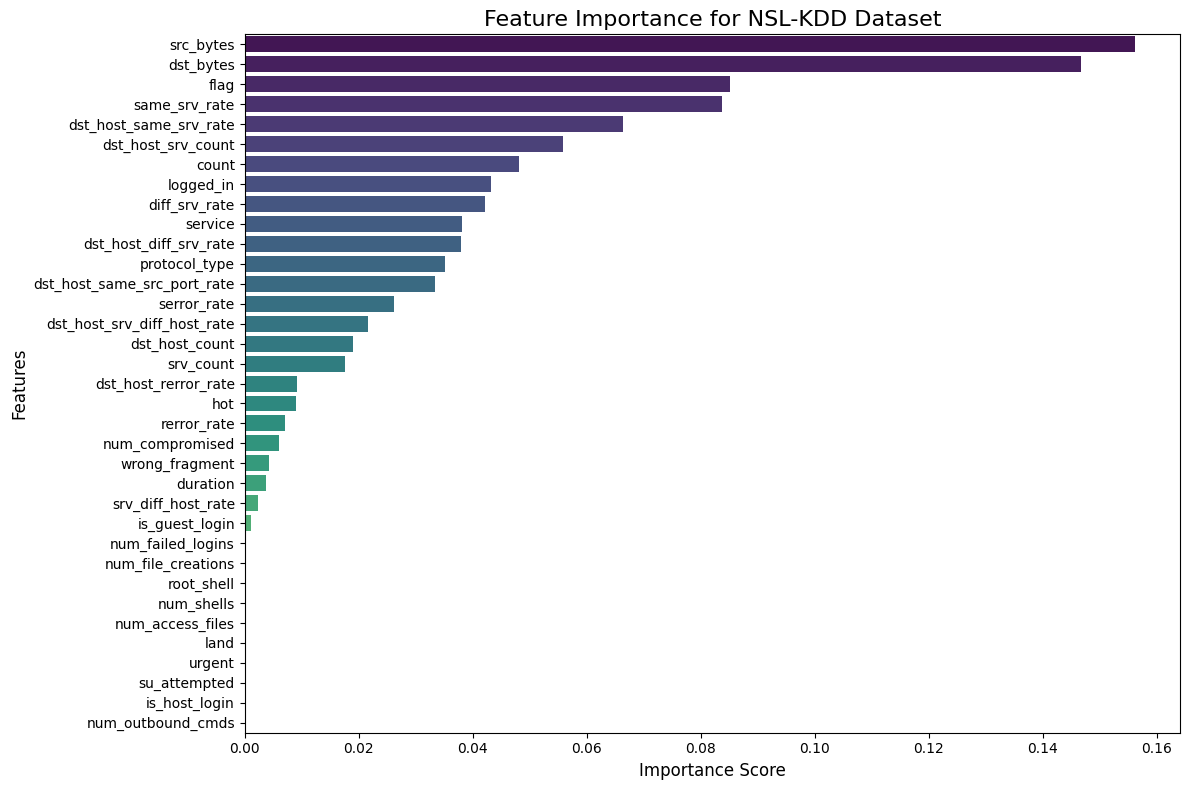

'/kaggle/working/nsl_kdd_feature_importance.png'

In [38]:
# Import necessary libraries
from sklearn.ensemble import RandomForestClassifier
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the preprocessed dataset
trn = pd.read_csv('/kaggle/working/nsl_kdd_preprocessed.csv')

# Separate the features and labels
X_trn = trn.drop(['labels'], axis=1)
Y_trn = trn['labels']

# Initialize a Random Forest classifier
rf = RandomForestClassifier(n_estimators=100, random_state=42)

# Fit the model on the training data
rf.fit(X_trn, Y_trn)

# Get feature importance scores
feature_importance = rf.feature_importances_

# Create a DataFrame for feature names and their corresponding importance scores
feature_scores = pd.DataFrame({
    'Feature': X_trn.columns,
    'Importance': feature_importance
})

# Sort the features by importance
feature_scores = feature_scores.sort_values(by='Importance', ascending=False)

# Visualize the feature importance
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=feature_scores, palette='viridis')

# Add labels and title to the plot
plt.title('Feature Importance for NSL-KDD Dataset', fontsize=16)
plt.xlabel('Importance Score', fontsize=12)
plt.ylabel('Features', fontsize=12)

# Save the result to the Kaggle directory
file_path = '/kaggle/working/nsl_kdd_feature_importance.png'
plt.tight_layout()
plt.savefig(file_path)

# Show the plot
plt.show()

file_path
